# Shape optimisation of the 18-bar cantilever truss with stress and buckling constraints

**Connectivity is fixed; node positions (and member areas, as in the literature) are continuous design variables.**

Benchmark: Imai & Schmit (1981), used by Hasançebi & Erbatur (2002), Rahami et al. (2008) and many later papers.
- 11 nodes, 18 members, supports at nodes 10 and 11, loads P = 20 kips downward at nodes 1, 2, 4, 6, 8.
- E = 10,000 ksi, ρ = 0.1 lb/in³.
- Stress |σ| ≤ 20 ksi. Compression also limited by Euler buckling: σ_b = K E A / L², with K = 4.
- 4 area groups, 2 ≤ A ≤ 22 in². Shape variables: x, y of nodes 3, 5, 7, 9 (bounds below).
- Minimise weight W = ρ Σ A L.

**Method (physics-informed, gradient-based):** the design variables are bounded with a sigmoid. The linear FE equilibrium K(x, A) u = f is solved inside the loss, and PyTorch autograd gives the exact gradients of weight and constraints with respect to every node coordinate and area. Loss = W/W₀ + w_c Σ max(0, g − 1)², with the penalty w_c raised from 10 to 10⁴ so the final design sits on the constraint boundary. The final design is re-checked with an independent NumPy FE solve.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # Windows: NumPy (MKL) and PyTorch both ship libiomp5md.dll

import time
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.set_default_dtype(torch.float64)

In [2]:
# 18-bar cantilever truss - units: in, kips, ksi, lb. Node numbers as in the literature (1-based)
nodes0 = np.array([[1250, 250], [1000, 250], [1000, 0], [750, 250], [750, 0], [500, 250],
                   [500, 0], [250, 250], [250, 0], [0, 250], [0, 0]], dtype=float)
members = np.array([(1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (3, 5), (4, 5), (4, 6), (5, 6),
                    (5, 7), (6, 7), (6, 8), (7, 8), (7, 9), (8, 9), (8, 10), (9, 10), (9, 11)]) - 1
groups = [[1, 4, 8, 12, 16], [2, 6, 10, 14, 18], [3, 7, 11, 15], [5, 9, 13, 17]]
supports = [10, 11]
loads = {k: (0.0, -20.0) for k in [1, 2, 4, 6, 8]}

E, rho = 1e4, 0.1
sigma_lim  = 20.0    # ksi  <-- stress limit (tension and compression), change this
K_buckling = 4.0     # Euler buckling sigma_b = K E A / L^2 (set None to switch off)
A_min, A_max, A_init = 2.0, 22.0, 12.0
optimise_areas = True   # False: pure shape optimisation with all areas fixed at A_init

# Shape variables: (name, [(node, coordinate 0=x 1=y, sign)], lower, upper)
shape_vars = [("x3", [(3, 0, 1)], 775, 1250), ("y3", [(3, 1, 1)], -225, 245),
              ("x5", [(5, 0, 1)], 525, 1000), ("y5", [(5, 1, 1)], -225, 245),
              ("x7", [(7, 0, 1)], 275, 750),  ("y7", [(7, 1, 1)], -225, 245),
              ("x9", [(9, 0, 1)], 25, 500),   ("y9", [(9, 1, 1)], -225, 245)]

# Reported optima (discrete areas, step 0.25 in^2): weight (lb), areas A1..A4 (in^2), x3 y3 x5 y5 x7 y7 x9 y9 (in)
literature = {
    "Hasançebi & Erbatur (2002)":          (4533.24, [12.25, 17.5, 5.75, 4.25], [910, 179, 638, 141, 408, 91, 198, 24]),
    "Kaveh & Kalatjari (2004)":            (4566.21, [13.0, 18.25, 5.5, 3.0],   [913, 182, 648, 152, 417, 103, 204, 39]),
    "Periodica Polytechnica (2018), best": (4520.33, [12.5, 17.75, 5.5, 3.75],  [911, 184, 642, 145, 412, 97, 201, 30]),
}

In [3]:
class TrussShapeProblem:
    """Shape + sizing optimisation of a truss with fixed connectivity (2D or 3D).
    Design variables: node coordinates (shape_vars) and member-group areas, both continuous and bounded."""

    def __init__(self, nodes0, members, groups, shape_vars, supports, loads, E, rho, A_min, A_max, A_init,
                 sigma_lim, K_buckling=None, u_lim=None, optimise_areas=True):
        self.nodes0 = torch.tensor(nodes0, dtype=torch.float64)
        self.members = members
        self.n_nodes, self.dim = nodes0.shape
        self.n_dof = self.n_nodes * self.dim
        self.E, self.rho = E, rho
        self.A_min, self.A_max = A_min, A_max
        self.sigma_lim, self.K_buckling, self.u_lim = sigma_lim, K_buckling, u_lim
        self.optimise_areas = optimise_areas

        self.grp = torch.zeros(len(members), dtype=torch.long)
        for g, mem in enumerate(groups):
            self.grp[np.array(mem) - 1] = g
        self.n_groups = len(groups)

        self.shape_vars = shape_vars
        self.lo = torch.tensor([s[2] for s in shape_vars], dtype=torch.float64)
        self.hi = torch.tensor([s[3] for s in shape_vars], dtype=torch.float64)
        v0 = torch.tensor([nodes0[s[1][0][0] - 1, s[1][0][1]] * s[1][0][2] for s in shape_vars])

        fixed = [self.dim * (k - 1) + d for k in supports for d in range(self.dim)]
        self.free = torch.tensor(np.setdiff1d(np.arange(self.n_dof), fixed))
        self.F = torch.zeros(self.n_dof)
        for k, p in loads.items():
            self.F[self.dim * (k - 1): self.dim * k] = torch.tensor(p, dtype=torch.float64)

        self.edofs = torch.tensor(np.hstack([self.dim * members[:, [0]] + np.arange(self.dim),
                                             self.dim * members[:, [1]] + np.arange(self.dim)]))

        # Bounded design variables through a sigmoid: value = lower + (upper - lower) * sigmoid(parameter)
        logit = lambda p: torch.log(p / (1 - p))
        a0 = torch.full((self.n_groups,), (A_init - A_min) / (A_max - A_min), dtype=torch.float64)
        s0 = ((v0 - self.lo) / (self.hi - self.lo)).clamp(0.02, 0.98)
        self.a_par = torch.nn.Parameter(logit(a0), requires_grad=optimise_areas)
        self.s_par = torch.nn.Parameter(logit(s0))

    def design(self):
        A = self.A_min + (self.A_max - self.A_min) * torch.sigmoid(self.a_par)
        v = self.lo + (self.hi - self.lo) * torch.sigmoid(self.s_par)
        X = self.nodes0.clone()
        for k, (name, links, lo, hi) in enumerate(self.shape_vars):
            for node, c, sign in links:
                X[node - 1, c] = sign * v[k]
        return A, v, X

    def analyse(self, A, X):
        # Linear FE, differentiable w.r.t. areas and node coordinates
        Am = A[self.grp]
        d = X[self.members[:, 1]] - X[self.members[:, 0]]
        L = d.norm(dim=1)
        c = d / L[:, None]
        t = torch.cat([-c, c], dim=1)
        ke = (self.E * Am / L)[:, None, None] * t[:, :, None] * t[:, None, :]
        nd2 = 2 * self.dim
        K = torch.zeros(self.n_dof, self.n_dof)
        K.index_put_((self.edofs[:, :, None].expand(-1, nd2, nd2), self.edofs[:, None, :].expand(-1, nd2, nd2)),
                     ke, accumulate=True)
        u = torch.zeros(self.n_dof)
        u = u.index_put((self.free,), torch.linalg.solve(K[self.free][:, self.free], self.F[self.free]))
        sigma = self.E * (t * u[self.edofs]).sum(1) / L
        return u, sigma, L, Am

    def constraint_ratios(self, u, sigma, L, Am):
        # every ratio must be <= 1
        s_c = torch.full_like(sigma, self.sigma_lim)
        if self.K_buckling is not None:
            s_c = torch.minimum(s_c, self.K_buckling * self.E * Am / L**2)       # Euler buckling
        g = {"tension": torch.relu(sigma) / self.sigma_lim, "compression": torch.relu(-sigma) / s_c}
        if self.u_lim is not None:
            g["displacement"] = u[self.free].abs() / self.u_lim
        return g

    def weight(self, L, Am):
        return self.rho * (Am * L).sum()

In [4]:
def optimise(prob, epochs=8000, lr=2e-2, w_start=1e1, w_end=1e4, print_every=1000, n_snapshots=6):
    params = [prob.s_par] + ([prob.a_par] if prob.optimise_areas else [])
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=1e-4)
    hist = {"W": [], "g_max": [], "snapshots": []}
    snap_at = set(np.linspace(0, epochs - 1, n_snapshots).astype(int))
    W0 = None
    t0 = time.time()

    for ep in range(epochs):
        w_c = w_start * (w_end / w_start) ** (ep / epochs)        # penalty weight raised geometrically
        A, v, X = prob.design()
        u, sigma, L, Am = prob.analyse(A, X)
        g = torch.cat(list(prob.constraint_ratios(u, sigma, L, Am).values()))
        W = prob.weight(L, Am)
        if W0 is None:
            W0 = W.item()
        loss = W / W0 + w_c * (torch.relu(g - 1) ** 2).sum()

        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()

        hist["W"].append(W.item())
        hist["g_max"].append(g.max().item())
        if ep in snap_at:
            hist["snapshots"].append((ep, X.detach().numpy().copy(), A.detach().numpy().copy(), W.item(), g.max().item()))
        if (ep + 1) % print_every == 0:
            print(f"Epoch {ep+1}: W = {W.item():.2f} lb, max constraint ratio = {g.max().item():.4f}")

    print(f"Optimisation time: {time.time() - t0:.1f} s")
    return hist

In [5]:
def fe_check(X, members, A_members, E, F, supports):
    # Independent NumPy FE solve of the final design (no autograd)
    n, dim = X.shape
    K = np.zeros((n * dim, n * dim))
    d = X[members[:, 1]] - X[members[:, 0]]
    L = np.linalg.norm(d, axis=1)
    c = d / L[:, None]
    for e, (i, j) in enumerate(members):
        t = np.r_[-c[e], c[e]]
        idx = np.r_[dim * i + np.arange(dim), dim * j + np.arange(dim)]
        K[np.ix_(idx, idx)] += E * A_members[e] / L[e] * np.outer(t, t)
    fixed = [dim * (k - 1) + q for k in supports for q in range(dim)]
    free = np.setdiff1d(np.arange(n * dim), fixed)
    u = np.zeros(n * dim)
    u[free] = np.linalg.solve(K[np.ix_(free, free)], F[free])
    du = u.reshape(n, dim)[members[:, 1]] - u.reshape(n, dim)[members[:, 0]]
    return u, E * (c * du).sum(1) / L, L

In [6]:
prob = TrussShapeProblem(nodes0, members, groups, shape_vars, supports, loads, E, rho, A_min, A_max, A_init,
                         sigma_lim, K_buckling=K_buckling, optimise_areas=optimise_areas)

# ~15 s on CPU
hist = optimise(prob, epochs=8000)

Epoch 1000: W = 4593.06 lb, max constraint ratio = 1.0048
Epoch 2000: W = 4580.13 lb, max constraint ratio = 1.0020
Epoch 3000: W = 4573.44 lb, max constraint ratio = 1.0022
Epoch 4000: W = 4553.27 lb, max constraint ratio = 1.0023
Epoch 5000: W = 4660.97 lb, max constraint ratio = 1.0001
Epoch 6000: W = 4526.67 lb, max constraint ratio = 0.9998
Epoch 7000: W = 4538.57 lb, max constraint ratio = 1.0000
Epoch 8000: W = 4526.88 lb, max constraint ratio = 1.0000
Optimisation time: 18.7 s


In [7]:
with torch.no_grad():
    A_opt, v_opt, X_opt = prob.design()
A_opt, v_opt, X_opt = A_opt.numpy(), v_opt.numpy(), X_opt.numpy()
A_mem = A_opt[prob.grp.numpy()]

# Independent check of the final design
F = prob.F.numpy()
u, sigma, L = fe_check(X_opt, members, A_mem, E, F, supports)
W = rho * (A_mem * L).sum()
s_c = np.minimum(sigma_lim, K_buckling * E * A_mem / L**2) if K_buckling else np.full(len(L), sigma_lim)
ratio = np.where(sigma >= 0, sigma / sigma_lim, -sigma / s_c)

print(f"Optimised weight: {W:.2f} lb   (initial geometry, A = {A_init}: {hist['W'][0]:.2f} lb)")
print(f"Max constraint ratio (independent FE check): {ratio.max():.4f}\n")

names = [f"A{k+1}" for k in range(len(A_opt))] + [s[0] for s in shape_vars]
print(f"{'Variable':>9} | {'Initial':>8} | {'This work':>9} | " + " | ".join(f"{k[:22]:>22}" for k in literature))
print("-" * (35 + 25 * len(literature)))
init_v = [A_init] * len(A_opt) + [nodes0[s[1][0][0] - 1, s[1][0][1]] for s in shape_vars]
for i, name in enumerate(names):
    ours = A_opt[i] if i < len(A_opt) else v_opt[i - len(A_opt)]
    lit = [(r[1] + r[2])[i] for r in literature.values()]
    print(f"{name:>9} | {init_v[i]:>8.2f} | {ours:>9.2f} | " + " | ".join(f"{x:>22.2f}" for x in lit))
print(f"{'W (lb)':>9} | {hist['W'][0]:>8.2f} | {W:>9.2f} | " + " | ".join(f"{r[0]:>22.2f}" for r in literature.values()))

print("\nMember check:")
print(f"{'Member':>6} | {'Nodes':>7} | {'A (in2)':>7} | {'L (in)':>7} | {'sigma (ksi)':>11} | {'allow (ksi)':>11} | {'ratio':>6}")
for e, (i, j) in enumerate(members):
    allow = sigma_lim if sigma[e] >= 0 else s_c[e]
    print(f"{e+1:>6} | {f'{i+1}-{j+1}':>7} | {A_mem[e]:>7.3f} | {L[e]:>7.1f} | {sigma[e]:>11.3f} | {allow:>11.3f} | {ratio[e]:>6.3f}")

Optimised weight: 4526.88 lb   (initial geometry, A = 12.0: 6021.32 lb)
Max constraint ratio (independent FE check): 1.0000

 Variable |  Initial | This work | Hasançebi & Erbatur (2 | Kaveh & Kalatjari (200 | Periodica Polytechnica
--------------------------------------------------------------------------------------------------------------
       A1 |    12.00 |     12.65 |                  12.25 |                  13.00 |                  12.50
       A2 |    12.00 |     17.29 |                  17.50 |                  18.25 |                  17.75
       A3 |    12.00 |      6.27 |                   5.75 |                   5.50 |                   5.50
       A4 |    12.00 |      3.53 |                   4.25 |                   3.00 |                   3.75
       x3 |  1000.00 |    901.69 |                 910.00 |                 913.00 |                 911.00
       y3 |     0.00 |    174.21 |                 179.00 |                 182.00 |                 184.00
       x

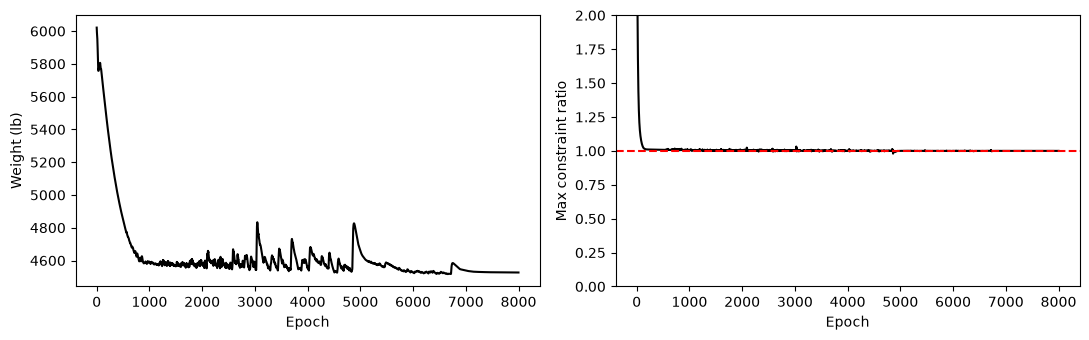

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(hist["W"], "k")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Weight (lb)")
ax2.plot(hist["g_max"], "k")
ax2.axhline(1.0, color="r", ls="--")
ax2.set_ylim(0, 2)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Max constraint ratio")
plt.tight_layout()
plt.show()

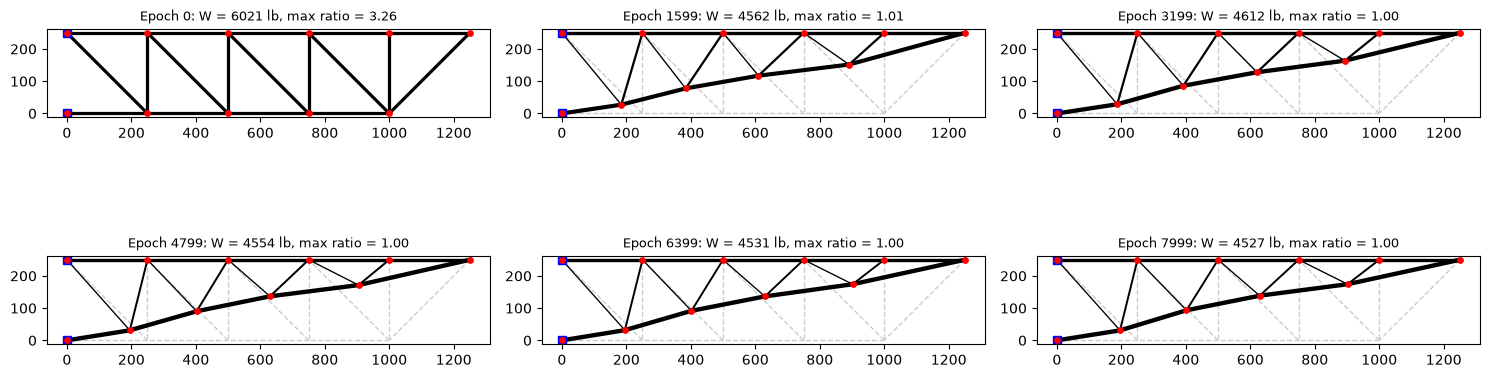

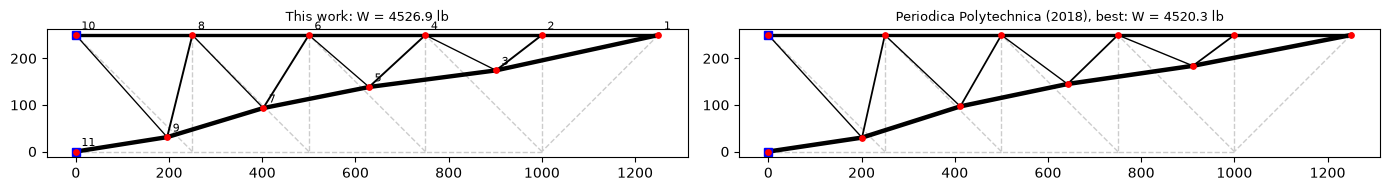

In [9]:
def plot_shape(ax, X, A, title, X_ref=None):
    if X_ref is not None:
        for i, j in members:
            ax.plot(X_ref[[i, j], 0], X_ref[[i, j], 1], color="0.8", lw=1, ls="--")
    Am = A[prob.grp.numpy()]
    for e, (i, j) in enumerate(members):
        ax.plot(X[[i, j], 0], X[[i, j], 1], "k", lw=0.4 + 3.5 * Am[e] / A_max)
    ax.scatter(X[:, 0], X[:, 1], c="r", s=15, zorder=3)
    for k in supports:
        ax.plot(X[k - 1, 0], X[k - 1, 1], "s", color="b", ms=6)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=9)

# Evolution of the geometry during optimisation (line width proportional to area; dashed = initial)
snaps = hist["snapshots"]
fig, axes = plt.subplots(2, 3, figsize=(15, 5.5))
for ax, (ep, X, A, Wk, gk) in zip(axes.ravel(), snaps):
    plot_shape(ax, X, A, f"Epoch {ep}: W = {Wk:.0f} lb, max ratio = {gk:.2f}", X_ref=nodes0)
plt.tight_layout()
plt.show()

# Final design next to the best literature geometry
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.5))
plot_shape(ax1, X_opt, A_opt, f"This work: W = {W:.1f} lb", X_ref=nodes0)
for k, X_n in enumerate(X_opt):
    ax1.annotate(str(k + 1), X_n, textcoords="offset points", xytext=(4, 4), fontsize=8)
name, (W_lit, A_lit, v_lit) = min(literature.items(), key=lambda kv: kv[1][0])
X_lit = nodes0.copy()
for k, s in enumerate(shape_vars):
    X_lit[s[1][0][0] - 1, s[1][0][1]] = v_lit[k]
plot_shape(ax2, X_lit, np.array(A_lit), f"{name}: W = {W_lit:.1f} lb", X_ref=nodes0)
plt.tight_layout()
plt.show()